# **Import Libraries**

In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# **Loading Dataset**

In [54]:
df = pd.read_csv('/content/ecommerce_dataset_updated.csv')

In [55]:
df.head()

,User_ID,Product_ID,Category,Price (Rs.),Discount (%),Final_Price(Rs.),Payment_Method,Purchase_Date
0,337c166f,f414122f-e,Sports,36.53,15,31.05,Net Banking,12-11-2024
1,d38a19bf,fde50f9c-5,Clothing,232.79,20,186.23,Net Banking,09-02-2024
2,d7f5f0b0,0d96fc90-3,Sports,317.02,25,237.76,Credit Card,01-09-2024
3,395d4994,964fc44b-d,Toys,173.19,25,129.89,UPI,01-04-2024
4,a83c145c,d70e2fc6-e,Beauty,244.80,20,195.84,Net Banking,27-09-2024


# **Understanding The Dataset**

In [56]:
df.shape

(3660, 8)

In [57]:
df.columns

Index(['User_ID', 'Product_ID', 'Category', 'Price (Rs.)', 'Discount (%)',
       'Final_Price(Rs.)', 'Payment_Method', 'Purchase_Date'],
      dtype='object')

In [58]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3660 entries, 0 to 3659
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   User_ID           3660 non-null   object 
 1   Product_ID        3660 non-null   object 
 2   Category          3660 non-null   object 
 3   Price (Rs.)       3660 non-null   float64
 4   Discount (%)      3660 non-null   int64  
 5   Final_Price(Rs.)  3660 non-null   float64
 6   Payment_Method    3660 non-null   object 
 7   Purchase_Date     3660 non-null   object 
dtypes: float64(2), int64(1), object(5)
memory usage: 228.9+ KB


In [59]:
df.describe()

,Price (Rs.),Discount (%),Final_Price(Rs.)
count,3660.000000,3660.000000,3660.000000
mean,254.800675,18.825137,206.906579
std,141.682621,14.731338,122.687844
min,10.090000,0.000000,5.890000
25%,134.012500,5.000000,104.512500
50%,253.845000,15.000000,199.185000
75%,377.595000,25.000000,304.117500
max,499.960000,50.000000,496.820000


In [60]:
df.describe(include='object')

,User_ID,Product_ID,Category,Payment_Method,Purchase_Date
count,3660,3660,3660,3660,3660
unique,3660,3660,7,5,326
top,e73ad07c,a5d07442-d,Home & Kitchen,Credit Card,21-08-2024
freq,1,1,549,760,21


# **Data Quality Checks**

In [61]:
# Missing Values

df.isnull().sum()

,0
User_ID,0
Product_ID,0
Category,0
Price (Rs.),0
Discount (%),0
Final_Price(Rs.),0
Payment_Method,0
Purchase_Date,0


In [62]:
# Duplicate Values

df.duplicated().sum()

np.int64(0)

In [63]:
# Unique Values

print("Unique Users:", df['User_ID'].nunique())
print("Unique Products:", df['Product_ID'].nunique())
print("Categories:", df['Category'].nunique())
print("Payment Methods:", df['Payment_Method'].nunique())

Unique Users: 3660
Unique Products: 3660
Categories: 7
Payment Methods: 5


In [64]:
# Check Categories

df['Category'].unique()

array(['Sports', 'Clothing', 'Toys', 'Beauty', 'Books', 'Home & Kitchen',
       'Electronics'], dtype=object)

In [65]:
# Check Payment Methods

df['Payment_Method'].unique()

array(['Net Banking', 'Credit Card', 'UPI', 'Cash on Delivery',
       'Debit Card'], dtype=object)

In [66]:
# Check Discount Values

sorted(df['Discount (%)'].unique())

[np.int64(0),
 np.int64(5),
 np.int64(10),
 np.int64(15),
 np.int64(20),
 np.int64(25),
 np.int64(30),
 np.int64(50)]

**Convert Purchase Date**

In [67]:
df['Purchase_Date'] = pd.to_datetime(df['Purchase_Date'], format = '%d-%m-%Y')

In [68]:
df['Purchase_Date'].dtype

dtype('<M8[ns]')

In [69]:
df['Purchase_Date'].min(), df['Purchase_Date'].max()

(Timestamp('2024-01-01 00:00:00'), Timestamp('2024-11-21 00:00:00'))

# **Validate Price Calculations**

In [70]:
df['Calculated_Final_Price'] = (df['Price (Rs.)'] * (1 - df['Discount (%)']/100))

In [71]:
df['Calculated_Final_Price']

,Calculated_Final_Price
0,31.0505
1,186.2320
2,237.7650
3,129.8925
4,195.8400
...,...
3655,486.7900
3656,180.9395
3657,389.7600
3658,313.3620


In [72]:
price_mismatch = (
    (df['Final_Price(Rs.)'] - df['Calculated_Final_Price']).abs() > 1
)

price_mismatch.sum()

np.int64(0)

# **Feature Engineering**

In [73]:
df['Discount_Amount'] = (
    df['Price (Rs.)'] - df['Final_Price(Rs.)']
)
df['Discount_Amount']

,Discount_Amount
0,5.48
1,46.56
2,79.26
3,43.30
4,48.96
...,...
3655,0.00
3656,31.93
3657,0.00
3658,134.30


In [74]:
df['Year_Month'] = df['Purchase_Date'].dt.to_period('M')  #Year-Month
df['Day_Of_Week'] = df['Purchase_Date'].dt.day_name()  #Day of the week

In [75]:
df[['Purchase_Date', 'Discount_Amount', 'Year_Month', 'Day_Of_Week']].head(10)

,Purchase_Date,Discount_Amount,Year_Month,Day_Of_Week
0,2024-11-12,5.48,2024-11,Tuesday
1,2024-02-09,46.56,2024-02,Friday
2,2024-09-01,79.26,2024-09,Sunday
3,2024-04-01,43.30,2024-04,Monday
4,2024-09-27,48.96,2024-09,Friday
5,2024-08-08,120.93,2024-08,Thursday
6,2024-03-28,3.85,2024-03,Thursday
7,2024-05-29,42.65,2024-05,Wednesday
8,2024-02-26,18.99,2024-02,Monday
9,2024-01-11,207.68,2024-01,Thursday


# **Overall Business KPIs**

In [76]:
total_revenue = df['Final_Price(Rs.)'].sum()
print(f"Total Revenue: ₹{total_revenue:,.2f}")

total_transactions = len(df)
print(f"Total Transactions: ₹{total_transactions:,}")

average_transaction_value = df['Final_Price(Rs.)'].mean()
print(f"Average Transaction Value: ₹{average_transaction_value:,.2f}")

average_discount = df['Discount (%)'].mean()
print(f"Average Discount: {average_discount:.2f}%")

total_discount_amount = df['Discount_Amount'].sum()
print(f"Total Discount Amount: ₹{total_discount_amount:,.2f}")

Total Revenue: ₹757,278.08
Total Transactions: ₹3,660
Average Transaction Value: ₹206.91
Average Discount: 18.83%
Total Discount Amount: ₹175,292.39


# **Monthly Sales Analysis**

In [77]:
monthly_analysis = (
    df.groupby('Year_Month').agg(
        Transactions = ('Product_ID', 'count'),
        Revenue = ('Final_Price(Rs.)', 'sum'),
        Average_Transaction = ('Final_Price(Rs.)', 'mean'),
        Average_Discount = ('Discount (%)', 'mean'),
        Total_Discount = ('Discount_Amount', 'sum')
    )
)

monthly_analysis

,Transactions,Revenue,Average_Transaction,Average_Discount,Total_Discount
Year_Month,,,,,
2024-01,340,69009.43,202.968912,17.426471,15192.89
2024-02,308,69186.34,224.630974,18.636364,15291.87
2024-03,355,71325.40,200.916620,18.985915,16341.69
2024-04,362,74365.13,205.428536,19.267956,17887.75
2024-05,333,68837.25,206.718468,20.765766,17788.96
2024-06,323,64256.66,198.937028,17.461300,13531.10
2024-07,346,72798.23,210.399509,18.786127,16440.03
2024-08,344,71506.96,207.869070,19.156977,16603.92
2024-09,342,68043.09,198.956404,18.260234,15592.22


**Monthly Revenue**

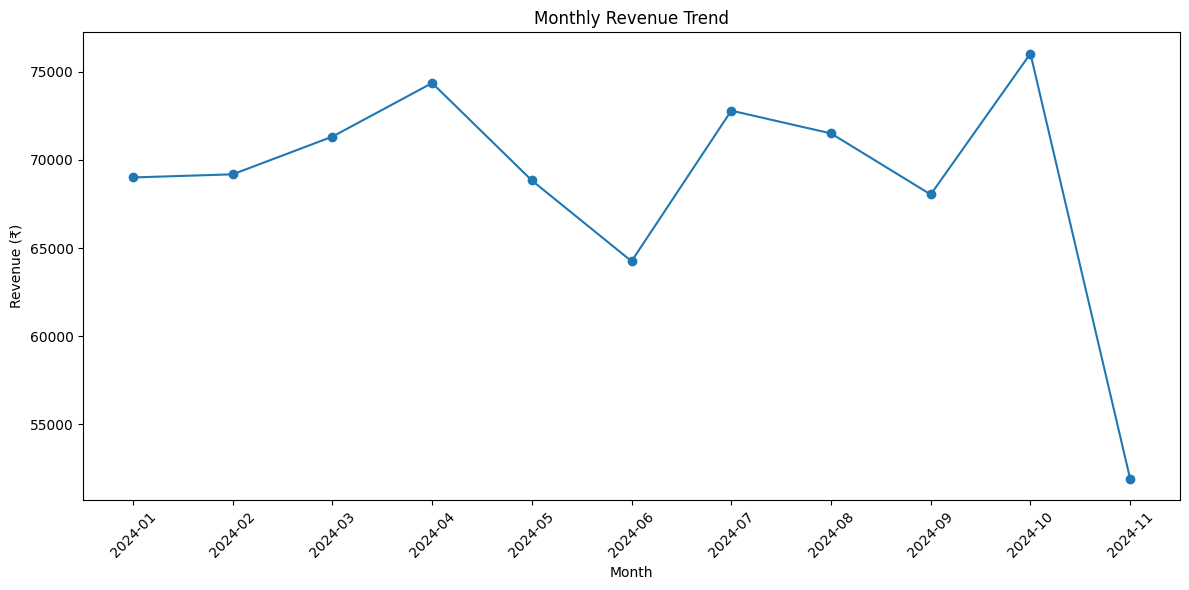

In [78]:
plt.figure(figsize=(12,6))

plt.plot(
    monthly_analysis.index.astype(str),
    monthly_analysis['Revenue'],
    marker = 'o'
)
plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue (₹)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


**Monthly Transactions**

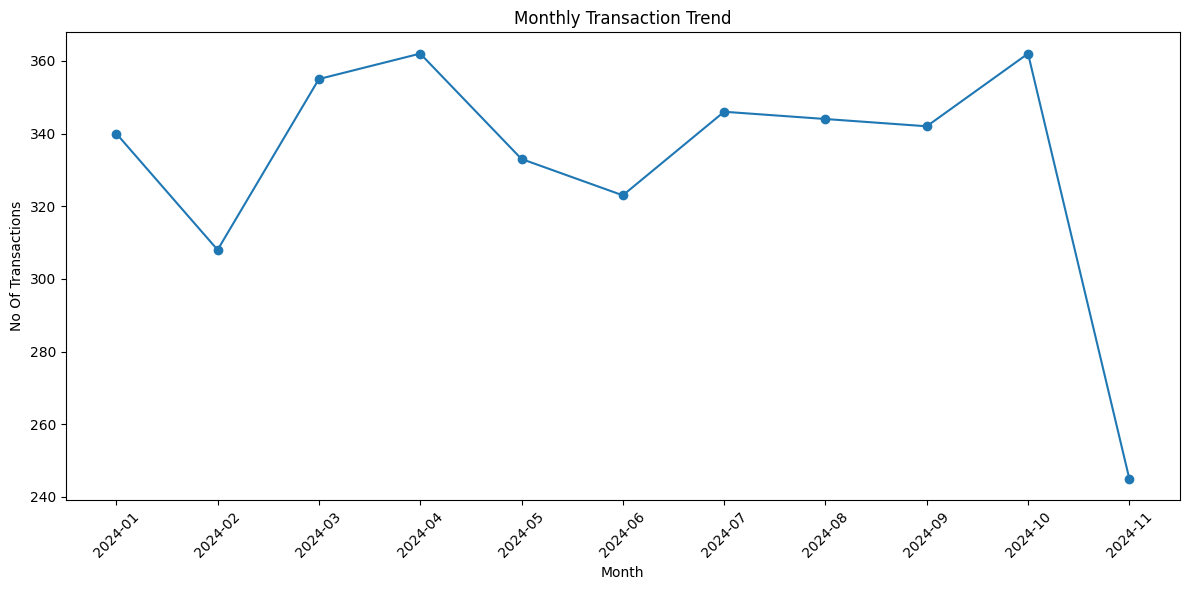

In [79]:
plt.figure(figsize=(12,6))

plt.plot(
    monthly_analysis.index.astype(str),
    monthly_analysis['Transactions'],
    marker = 'o'
)
plt.title('Monthly Transaction Trend')
plt.xlabel('Month')
plt.ylabel('No Of Transactions')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


**Monthly Average Discount**

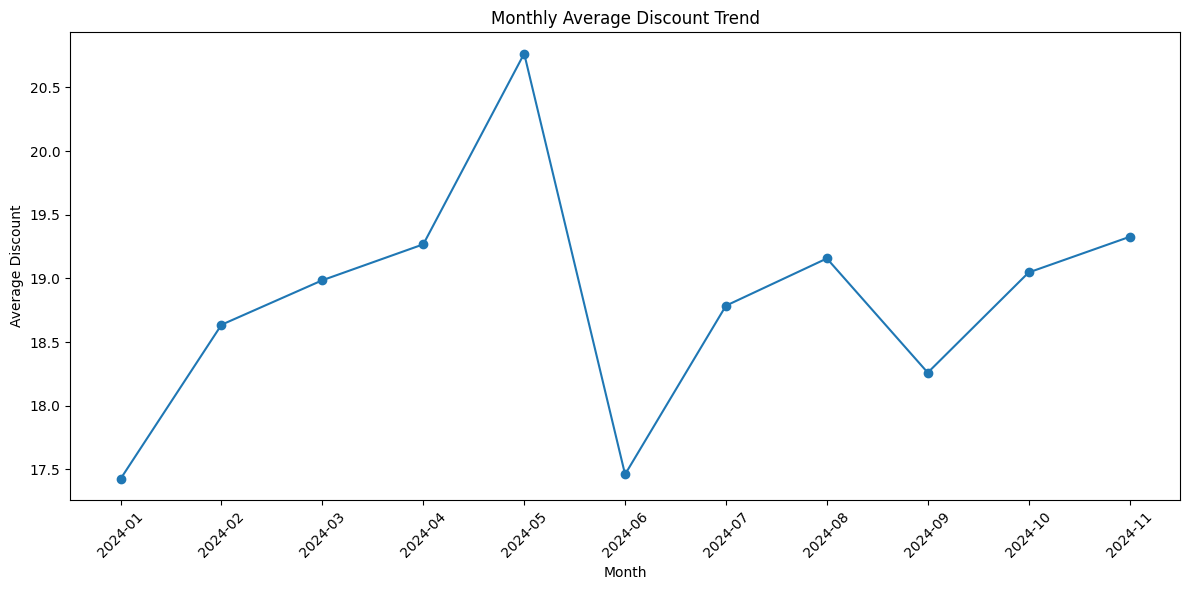

In [80]:
plt.figure(figsize=(12,6))

plt.plot(
    monthly_analysis.index.astype(str),
    monthly_analysis['Average_Discount'],
    marker = 'o'
)
plt.title('Monthly Average Discount Trend')
plt.xlabel('Month')
plt.ylabel('Average Discount')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# **Day-of-Week Sales & Discount Analysis**

In [81]:
weekday_analysis = (
    df.groupby('Day_Of_Week')
      .agg(
          Transactions=('Product_ID', 'count'),
          Revenue=('Final_Price(Rs.)', 'sum'),
          Average_Transaction=('Final_Price(Rs.)', 'mean'),
          Average_Discount=('Discount (%)', 'mean'),
          Discount_Amount=('Discount_Amount', 'sum')
      )
)

weekday_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday'
]

weekday_analysis = weekday_analysis.reindex(weekday_order)

weekday_analysis

,Transactions,Revenue,Average_Transaction,Average_Discount,Discount_Amount
Day_Of_Week,,,,,
Monday,522,108624.43,208.092778,18.802682,24866.73
Tuesday,542,112299.98,207.195535,18.523985,25416.52
Wednesday,509,103007.68,202.372652,18.261297,22586.58
Thursday,525,113187.49,215.595219,19.219048,26325.42
Friday,519,106048.81,204.332967,18.998073,25098.01
Saturday,477,98827.45,207.185430,19.067086,23814.77
Sunday,566,115282.24,203.678869,18.913428,27184.36


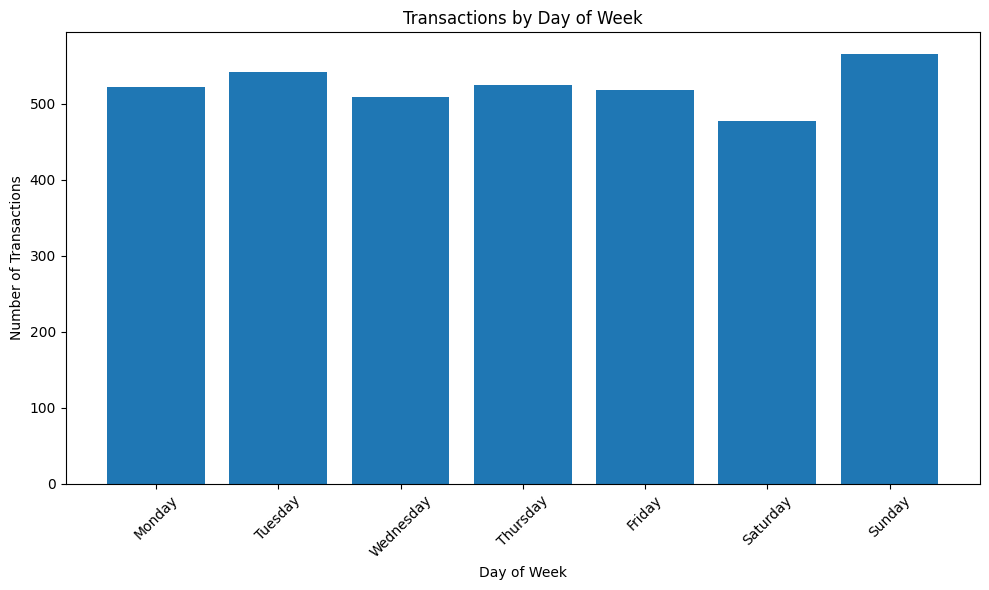

In [82]:
plt.figure(figsize=(10, 6))

plt.bar(
    weekday_analysis.index,
    weekday_analysis['Transactions']
)

plt.title('Transactions by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# **Category Analysis**

In [83]:
category_analysis = (
    df.groupby('Category')
      .agg(
          Transactions=('Product_ID', 'count'),
          Revenue=('Final_Price(Rs.)', 'sum'),
          Average_Transaction=('Final_Price(Rs.)', 'mean'),
          Average_Discount=('Discount (%)', 'mean')
      )
      .sort_values('Revenue', ascending=False)
)

category_analysis['Revenue_%'] = (
    category_analysis['Revenue'] /
    category_analysis['Revenue'].sum() * 100
)

category_analysis

,Transactions,Revenue,Average_Transaction,Average_Discount,Revenue_%
Category,,,,,
Clothing,531,115314.84,217.165424,17.919021,15.227542
Books,534,111149.35,208.144850,19.035581,14.677481
Home & Kitchen,549,110328.08,200.961894,19.608379,14.569031
Sports,520,108518.79,208.689981,19.326923,14.330111
Toys,523,107289.69,205.142811,18.126195,14.167806
Beauty,505,104215.10,206.366535,18.475248,13.761801
Electronics,498,100462.23,201.731386,19.267068,13.266227


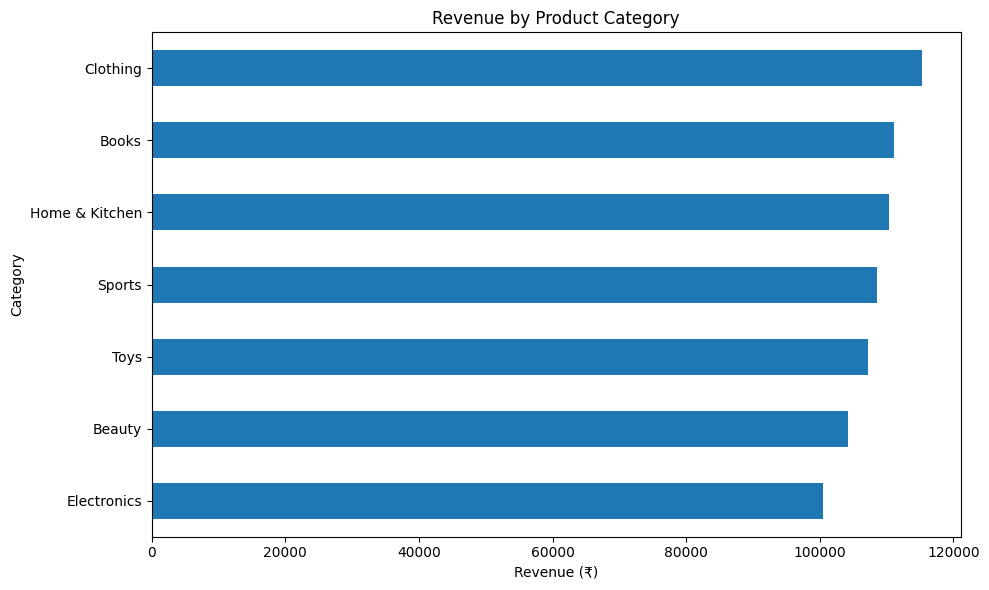

In [84]:
plt.figure(figsize=(10, 6))

category_analysis['Revenue'].sort_values().plot(kind='barh')

plt.title('Revenue by Product Category')
plt.xlabel('Revenue (₹)')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

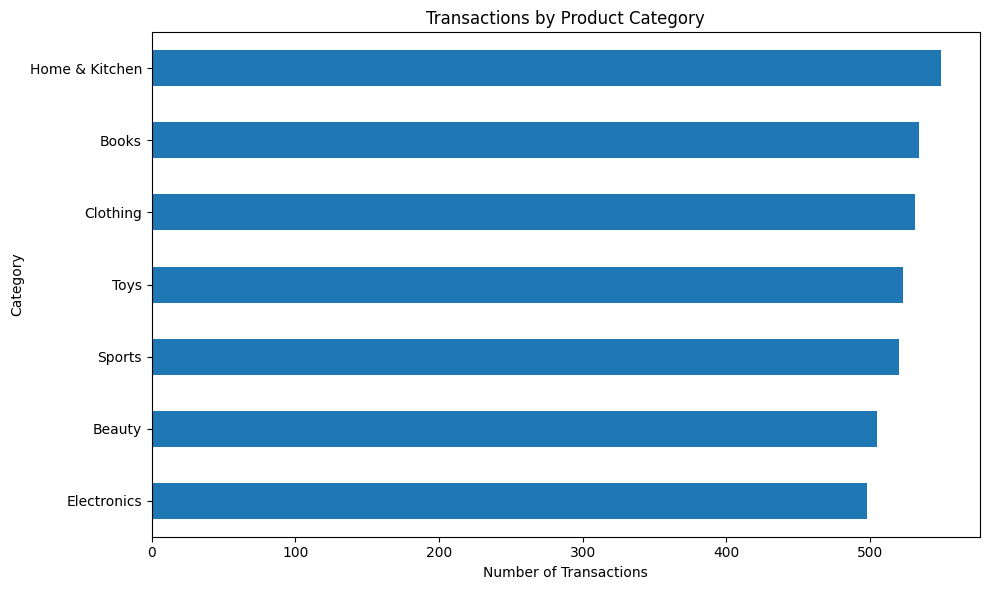

In [85]:
plt.figure(figsize=(10, 6))

category_analysis['Transactions'].sort_values().plot(kind='barh')

plt.title('Transactions by Product Category')
plt.xlabel('Number of Transactions')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

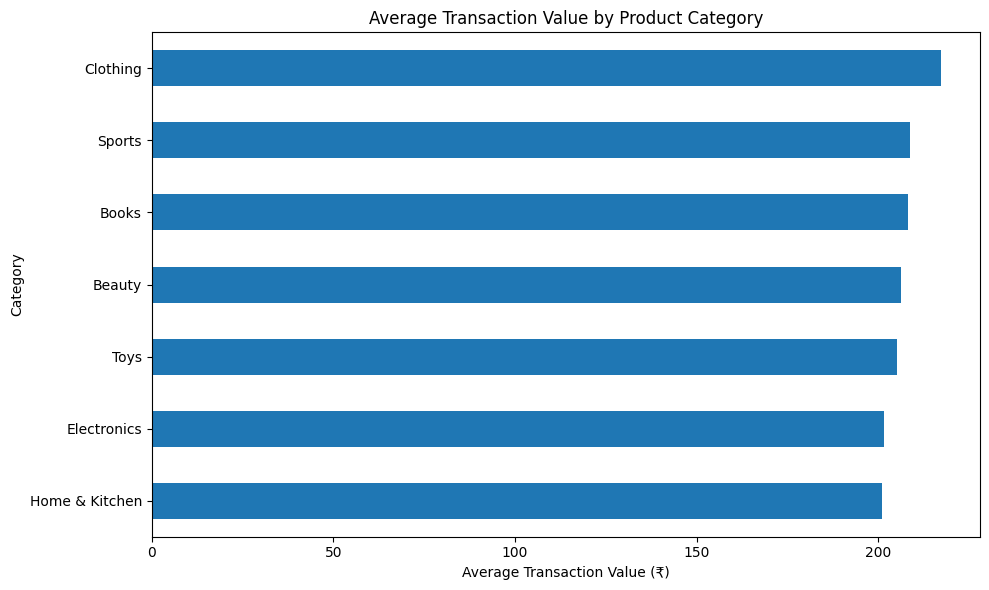

In [86]:
plt.figure(figsize=(10, 6))

category_analysis['Average_Transaction'].sort_values().plot(kind='barh')

plt.title('Average Transaction Value by Product Category')
plt.xlabel('Average Transaction Value (₹)')
plt.ylabel('Category')

plt.tight_layout()
plt.show()

# **Payment Method Analysis**

In [87]:
payment_analysis = (
    df.groupby('Payment_Method')
      .agg(
          Transactions=('Product_ID', 'count'),
          Revenue=('Final_Price(Rs.)', 'sum'),
          Average_Transaction=('Final_Price(Rs.)', 'mean')
      )
      .sort_values('Transactions', ascending=False)
)

payment_analysis

,Transactions,Revenue,Average_Transaction
Payment_Method,,,
Credit Card,760,156018.02,205.286868
UPI,757,154684.81,204.339247
Debit Card,731,153362.26,209.797893
Net Banking,716,146804.40,205.034078
Cash on Delivery,696,146408.59,210.357170


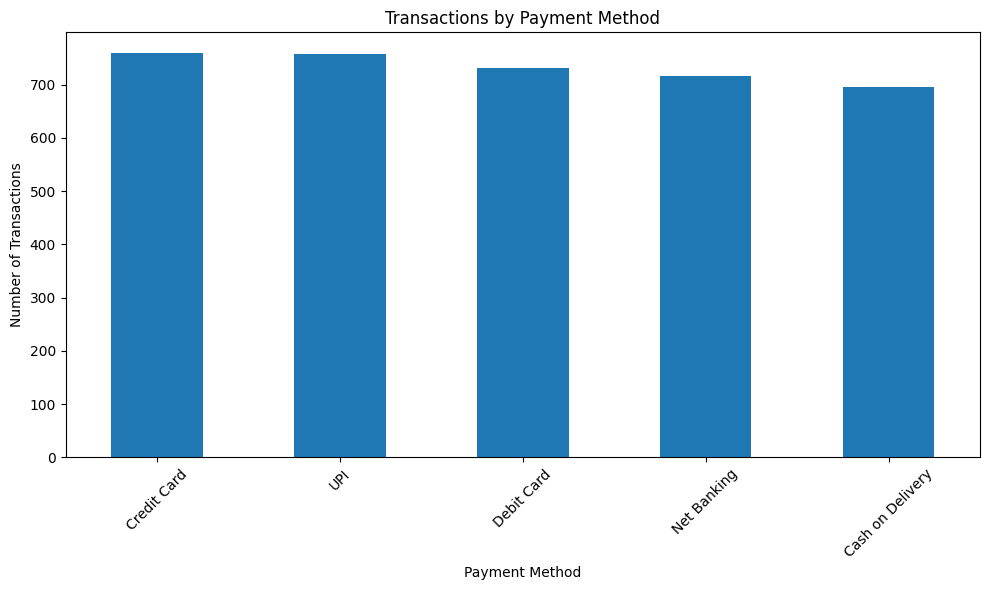

In [88]:
plt.figure(figsize=(10, 6))

payment_analysis['Transactions'].plot(kind='bar')

plt.title('Transactions by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

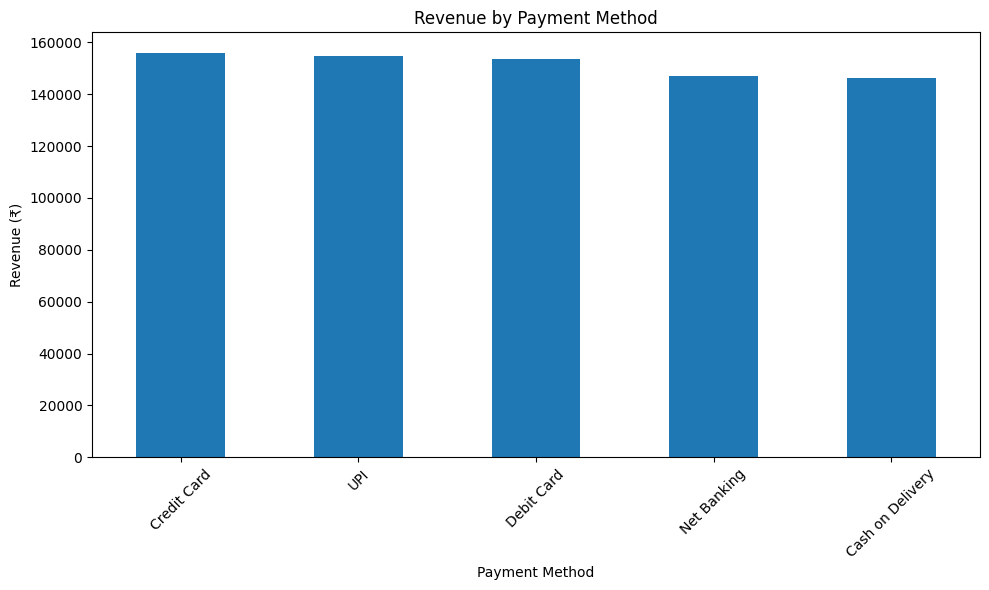

In [89]:
plt.figure(figsize=(10, 6))

payment_analysis['Revenue'].plot(kind='bar')

plt.title('Revenue by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Revenue (₹)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# **Discount Analysis**

In [90]:
df['Discount_Group'] = pd.cut(
    df['Discount (%)'],
    bins = [-1, 0, 15, 30, 45, 50, 100],
    labels = ['No Discount', 'Low Discount', 'Medium Discount', 'High Discount', 'Very High Discount', 'Other']
)

In [91]:
df['Discount_Group'].value_counts().sort_index()

,count
Discount_Group,
No Discount,480
Low Discount,1417
Medium Discount,1333
High Discount,0
Very High Discount,430
Other,0


In [92]:
discount_analysis = (
    df.groupby('Discount_Group', observed=False)
      .agg(
          Transactions=('Product_ID', 'count'),
          Revenue=('Final_Price(Rs.)', 'sum'),
          Average_Transaction=('Final_Price(Rs.)', 'mean'),
          Average_Discount=('Discount (%)', 'mean')
      )
)

discount_analysis

,Transactions,Revenue,Average_Transaction,Average_Discount
Discount_Group,,,,
No Discount,480,122503.80,255.216250,0.000000
Low Discount,1417,328709.64,231.975752,10.014114
Medium Discount,1333,250805.92,188.151478,24.913728
High Discount,0,0.00,NaN,NaN
Very High Discount,430,55258.72,128.508651,50.000000
Other,0,0.00,NaN,NaN


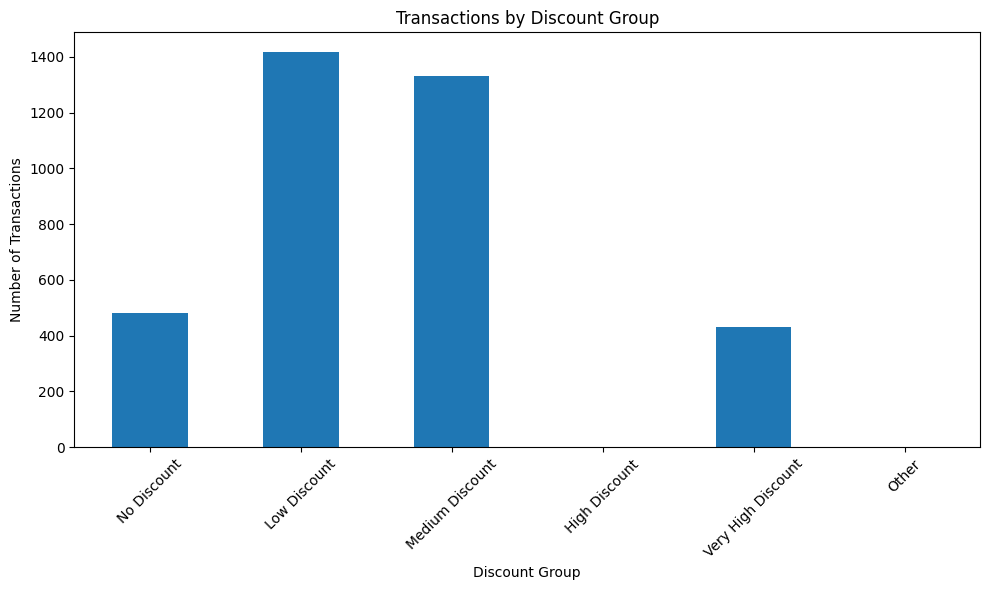

In [93]:
plt.figure(figsize=(10, 6))

discount_analysis['Transactions'].plot(kind='bar')

plt.title('Transactions by Discount Group')
plt.xlabel('Discount Group')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

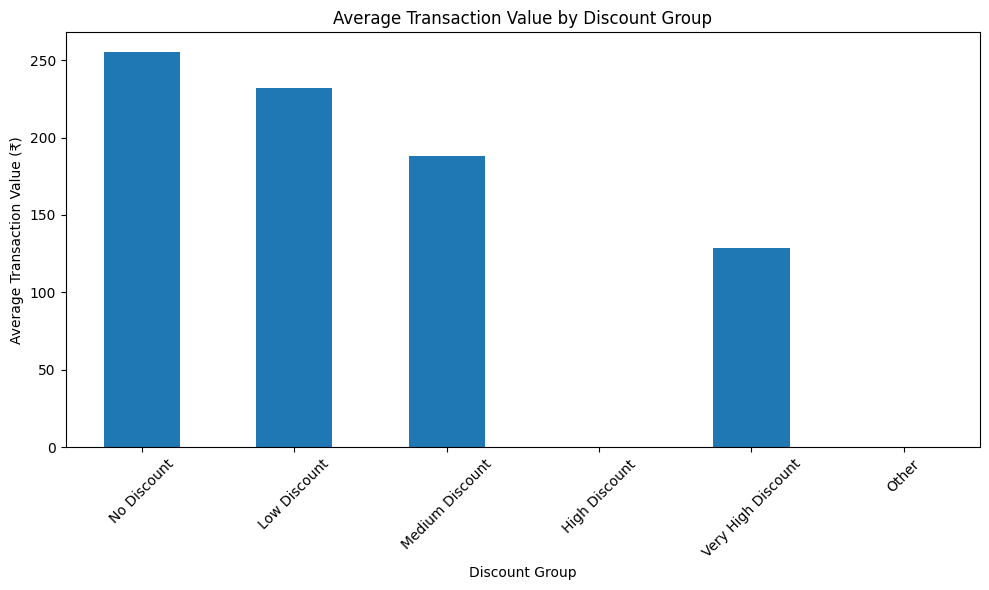

In [94]:
plt.figure(figsize=(10, 6))

discount_analysis['Average_Transaction'].plot(kind='bar')

plt.title('Average Transaction Value by Discount Group')
plt.xlabel('Discount Group')
plt.ylabel('Average Transaction Value (₹)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# **Price And Discount Relationship**

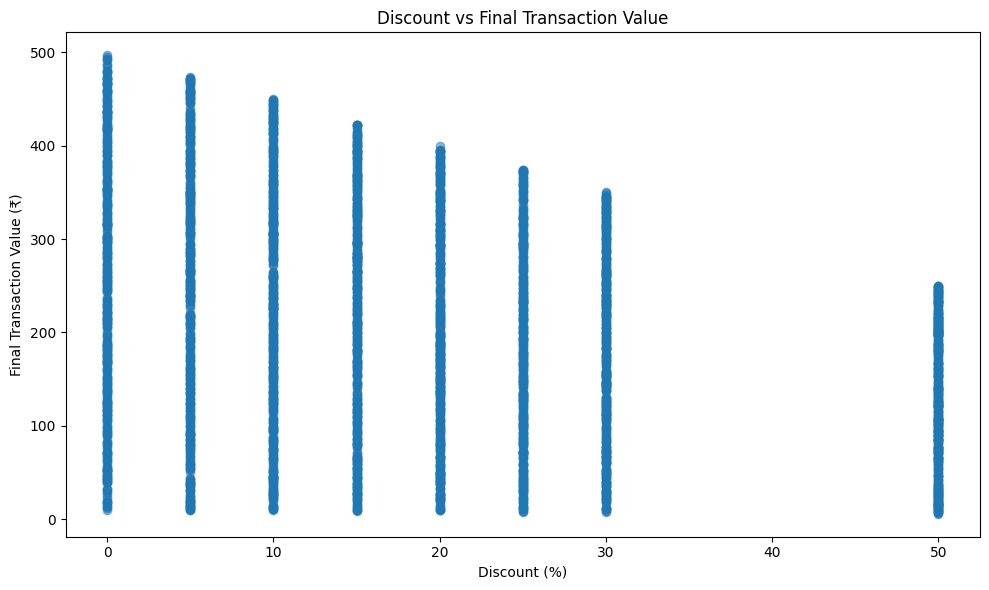

In [95]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df['Discount (%)'],
    df['Final_Price(Rs.)'],
    alpha=0.5
)

plt.title('Discount vs Final Transaction Value')
plt.xlabel('Discount (%)')
plt.ylabel('Final Transaction Value (₹)')

plt.tight_layout()
plt.show()

In [96]:
correlation = df['Discount (%)'].corr(
    df['Final_Price(Rs.)']
)

print(f"Correlation: {correlation:.3f}")

Correlation: -0.312


# **Statistical Analysis**

**Payment Method vs Category**

In [97]:
from scipy.stats import chi2_contingency

payment_category_table = pd.crosstab(
    df['Category'],
    df['Payment_Method']
)

chi2, p_chi, dof, expected = chi2_contingency(
    payment_category_table
)

print(f"Chi-square statistic: {chi2:.2f}")
print(f"P-value: {p_chi:.4f}")

Chi-square statistic: 14.29
P-value: 0.9398


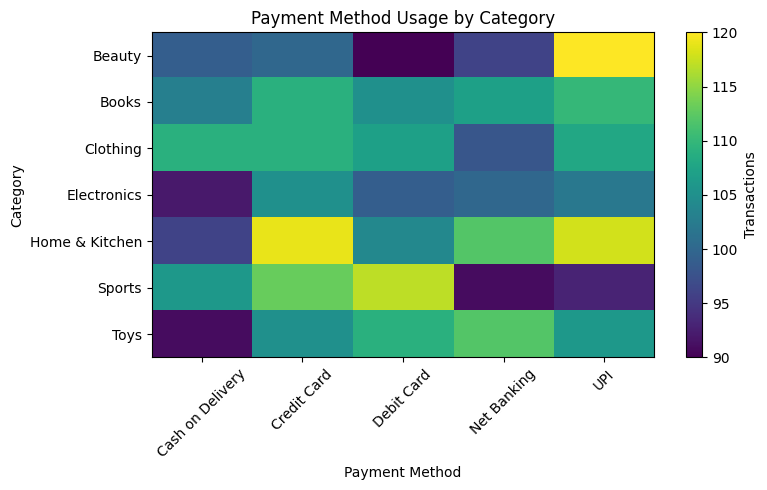

In [98]:
plt.figure(figsize=(8, 5))

plt.imshow(
    payment_category_table,
    aspect='auto'
)

plt.xticks(
    range(len(payment_category_table.columns)),
    payment_category_table.columns,
    rotation=45
)

plt.yticks(
    range(len(payment_category_table.index)),
    payment_category_table.index
)

plt.colorbar(label='Transactions')

plt.title('Payment Method Usage by Category')
plt.xlabel('Payment Method')
plt.ylabel('Category')

plt.tight_layout()
plt.show()

**Weekend vs Weekday Transaction Value**

In [99]:
df['Is_Weekend'] = df['Day_Of_Week'].isin(
    ['Saturday', 'Sunday']
)

In [100]:
from scipy.stats import ttest_ind

weekend_spend = df.loc[
    df['Is_Weekend'],
    'Final_Price(Rs.)'
]

weekday_spend = df.loc[
    ~df['Is_Weekend'],
    'Final_Price(Rs.)'
]

t_stat, p_ttest = ttest_ind(
    weekend_spend,
    weekday_spend,
    equal_var=False
)

print(f"Weekend average: ₹{weekend_spend.mean():.2f}")
print(f"Weekday average: ₹{weekday_spend.mean():.2f}")
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_ttest:.4f}")

Weekend average: ₹205.28
Weekday average: ₹207.55
T-statistic: -0.5117
P-value: 0.6089


# **Distribution & Outliers**

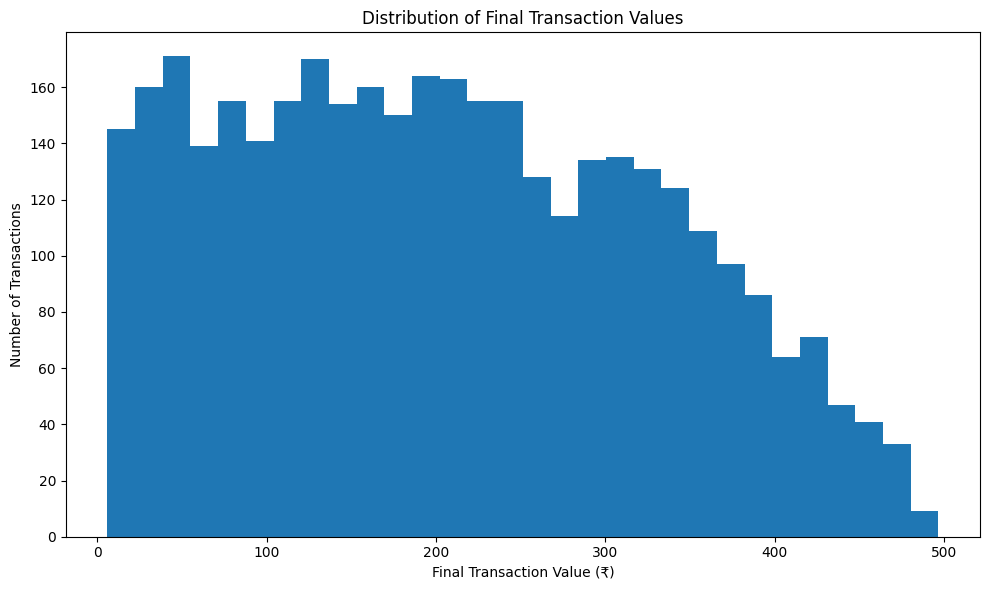

In [101]:
plt.figure(figsize=(10, 6))

plt.hist(
    df['Final_Price(Rs.)'],
    bins=30
)

plt.title('Distribution of Final Transaction Values')
plt.xlabel('Final Transaction Value (₹)')
plt.ylabel('Number of Transactions')

plt.tight_layout()
plt.show()

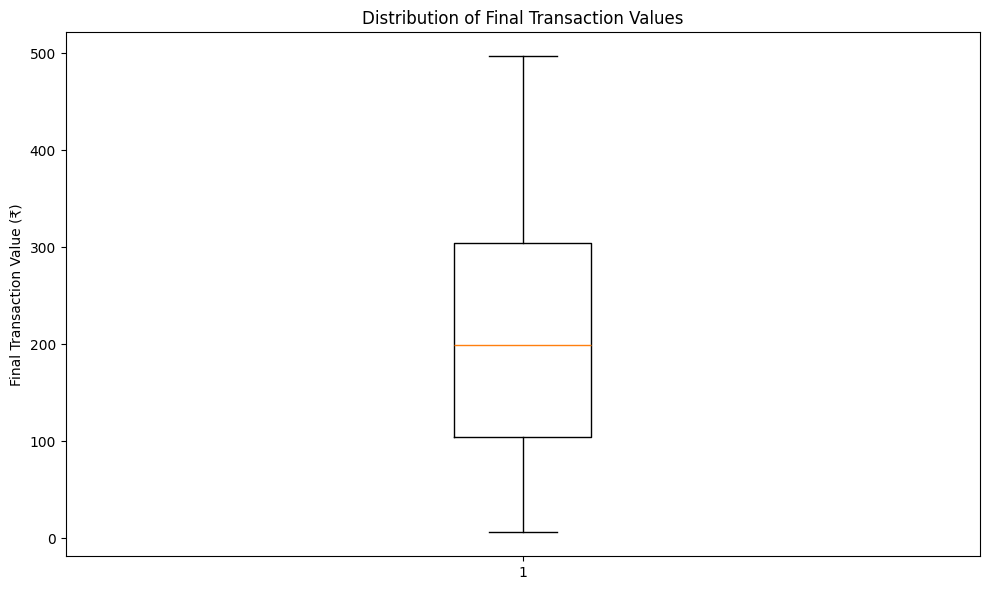

In [102]:
plt.figure(figsize=(10, 6))

plt.boxplot(df['Final_Price(Rs.)'])

plt.title('Distribution of Final Transaction Values')
plt.ylabel('Final Transaction Value (₹)')

plt.tight_layout()
plt.show()